# Synora · Intentions d'achat sur un site marchand (sujet 18)
## Notebook Colab 1 · Données (jalon 1, 25/11)

**Équipe Synora** · Machine Learning, L3 GLSI, IIT Sfax, 2026-2027.
Repérer, **pendant la visite**, les sessions d'un site marchand qui vont se terminer par un achat (Online Shoppers Purchasing Intention Dataset, UCI).

Ce notebook couvre les étapes 1 (Collecte) et 2 (Préparation) du cycle de vie d'un modèle, avec les notions des chapitres 1 à 3 seulement : **aucun modèle, aucun score**. Les modèles (J2) et l'évaluation (J3) sont dans le notebook suivant, qui reprend le même nettoyage et le même découpage. Exécutez-le de haut en bas (*Exécution → Tout exécuter*).

| Étape | Partie du notebook |
| --- | --- |
| 1 · Collecte | Partie 1 : charger les données officielles, contrôler leur qualité, explorer |
| 2 · Préparation | Partie 2 : nettoyer, séparer train / test **avant** de préparer, encoder et normaliser |

**Rôles de l'équipe (ils tournent à chaque jalon)**

| Membre | Cadrage (S2) | J1 Données | J2 Modèles | J3 Évaluation et application |
| --- | --- | --- | --- | --- |
| Khaled Mnejja | Analyste données | Modélisateur | Évaluateur | Documentaliste |
| Omar Zouari | Documentaliste | Présentateur | Analyste données | Modélisateur |
| Omar Idriss | Modélisateur | Évaluateur | Documentaliste | Présentateur |
| Tawfik Zayen | Évaluateur | Documentaliste | Présentateur | Analyste données |
| Rayen Hsairi | Présentateur | Analyste données | Modélisateur | Évaluateur |

In [92]:
# Imports (toutes ces bibliothèques sont déjà installées dans Colab)
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.6.1 | pandas 2.2.3 | numpy 2.4.6


## 0. Mise en place

In [93]:
# ===================== CONFIG : tous les réglages du projet au même endroit =====================
RANDOM_STATE = 42
TEST_SIZE = 0.2

DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00468/online_shoppers_intention.csv"
LOCAL_PATH = "online_shoppers_intention.csv"   # utilisé si le fichier a été téléversé dans Colab

TARGET = "Revenue"
NUM_COLS = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "SpecialDay",
]
LEAKY_COL = "PageValues"   # fuite repérée au cadrage : exclue de la préparation
CAT_COLS = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]
BOOL_COLS = ["Weekend"]

FEATURES = NUM_COLS + CAT_COLS + BOOL_COLS   # colonnes gardées (PageValues exclue)

# Garde-fou : le découpage doit toujours être le même (reproductibilité).
EXPECTED_SPLIT = (9764, 2441)   # (lignes d'entraînement, lignes de test)

In [94]:
# ===================== FONCTIONS DU PROJET =====================
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def load_raw():
    """Étape 1 : charge le CSV officiel (fichier local, sinon page UCI, sinon téléversement)."""
    if Path(LOCAL_PATH).exists():
        return pd.read_csv(LOCAL_PATH)
    try:
        return pd.read_csv(DATA_URL)
    except Exception as err:
        print("Téléchargement impossible :", err, "-> téléversez online_shoppers_intention.csv")
        from google.colab import files
        files.upload()
        return pd.read_csv(LOCAL_PATH)


def clean(df):
    """Nettoyage sans apprentissage (aucune statistique calculée) : sûr avant le découpage."""
    df = df.copy()
    df["Month"] = df["Month"].replace({"June": "Jun"})   # seul mois écrit en entier
    df["Weekend"] = df["Weekend"].astype(int)
    df[TARGET] = df[TARGET].astype(int)
    for col in CAT_COLS:                                 # les codes sont des catégories
        df[col] = df[col].astype(str)
    return df.drop_duplicates().reset_index(drop=True)   # avant le découpage, sinon fuite


def split(df):
    """Découpage stratifié, toujours avec la même graine."""
    X = df.drop(columns=TARGET)
    y = df[TARGET]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
    assert (len(X_train), len(X_test)) == EXPECTED_SPLIT, "Découpage différent de celui attendu !"
    return X_train, X_test, y_train, y_test


def make_preprocessor():
    """Étape 2 : à n'ajuster que sur l'entraînement."""
    return ColumnTransformer([
        ("num", StandardScaler(), NUM_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
        ("bool", "passthrough", BOOL_COLS),
    ], remainder="drop")   # remainder="drop" : toute autre colonne (ici PageValues) est retirée

# Partie 1 · Collecte (étape 1)

**Fiche du jeu de données**

| Rubrique | Description |
| --- | --- |
| Origine | Online Shoppers Purchasing Intention Dataset, déposé en 2018 sur l'UCI Machine Learning Repository par C. O. Sakar et al. (licence CC BY 4.0) |
| Contexte | Les visites d'un site marchand pendant une année, enregistrées par Google Analytics ; chaque ligne est une session d'un visiteur différent |
| Taille | 12 330 sessions × 18 colonnes (17 variables + 1 cible) |
| Variables | 10 numériques : pages vues et temps passé par type de page (administrative, information, produit), taux de rebond, taux de sortie, `PageValues`, `SpecialDay` ; 7 catégorielles : mois, système d'exploitation, navigateur, région, source de trafic, type de visiteur, week-end |
| Cible | `Revenue` : `True` si la session s'est terminée par un achat (environ 15 %) |
| Pièges | Classes déséquilibrées ; `PageValues` calculée à partir des achats (fuite possible) ; codes numériques qui sont des catégories ; pas de janvier ni d'avril |

**Description des variables** (définitions de la page UCI)

| Variable | Type | Description |
| --- | --- | --- |
| `Administrative`, `Informational`, `ProductRelated` | entier | Nombre de pages vues de chaque type pendant la session : compte, informations sur le site, produits |
| `Administrative_Duration`, `Informational_Duration`, `ProductRelated_Duration` | réel (secondes) | Temps total passé sur chaque type de page |
| `BounceRates` | réel (0 à 0,2) | Taux de rebond moyen des pages vues : part des visites qui quittent le site dès cette page |
| `ExitRates` | réel (0 à 0,2) | Taux de sortie moyen des pages vues : part des pages vues qui ont été la dernière de la visite |
| `PageValues` | réel | Valeur moyenne des pages vues avant une transaction (calculée par Google Analytics à partir des achats) |
| `SpecialDay` | réel (0 à 1) | Proximité d'un jour spécial (Saint-Valentin, fête des mères…) |
| `Month` | catégorie | Mois de la visite |
| `OperatingSystems`, `Browser`, `Region`, `TrafficType` | code (catégorie) | Système d'exploitation, navigateur, région du visiteur, source du trafic |
| `VisitorType` | catégorie | Nouveau visiteur, visiteur qui revient, autre |
| `Weekend` | booléen | Visite pendant le week-end |
| `Revenue` | booléen | **Cible** : la session s'est terminée par un achat |

### 1.1 Premier contact

In [95]:
raw = load_raw()
print(raw.shape)
raw.head()

(12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


### 1.2 Qualité : types, valeurs manquantes, doublons

In [96]:
raw.info()
print("\nValeurs manquantes :", int(raw.isna().sum().sum()))
print("Lignes en double   :", int(raw.duplicated().sum()))
raw.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


#### 1.2 bis Les doublons : erreurs ou vraies visites ?

Avant de retirer les 125 doublons, regardons à quoi ils ressemblent.

In [97]:
dups = raw[raw.duplicated(keep=False)]
print("Lignes concernées par un doublon :", len(dups))
print("Dont achats :", int(dups[TARGET].sum()))
print("Pages produits (médiane) :", dups["ProductRelated"].median(),
      "| durée produits (médiane) :", dups["ProductRelated_Duration"].median(), "s")
print("Taux de rebond = 0,2 (rebond maximal) :", int((dups["BounceRates"] == 0.2).sum()), "sur", len(dups))

# Mêmes variables mais étiquette différente ? (ce serait un vrai problème de qualité)
features = [c for c in raw.columns if c != TARGET]
conflits = (raw.groupby(features)[TARGET].nunique() > 1).sum()
print("Groupes identiques avec des étiquettes contradictoires :", int(conflits))

Lignes concernées par un doublon : 201
Dont achats : 0
Pages produits (médiane) : 1.0 | durée produits (médiane) : 0.0 s
Taux de rebond = 0,2 (rebond maximal) : 201 sur 201
Groupes identiques avec des étiquettes contradictoires : 0


#### 1.2 ter Valeurs aberrantes et durées nulles

Les durées sont très étirées vers la droite : une échelle logarithmique (`log1p`) permet de voir toute la distribution.

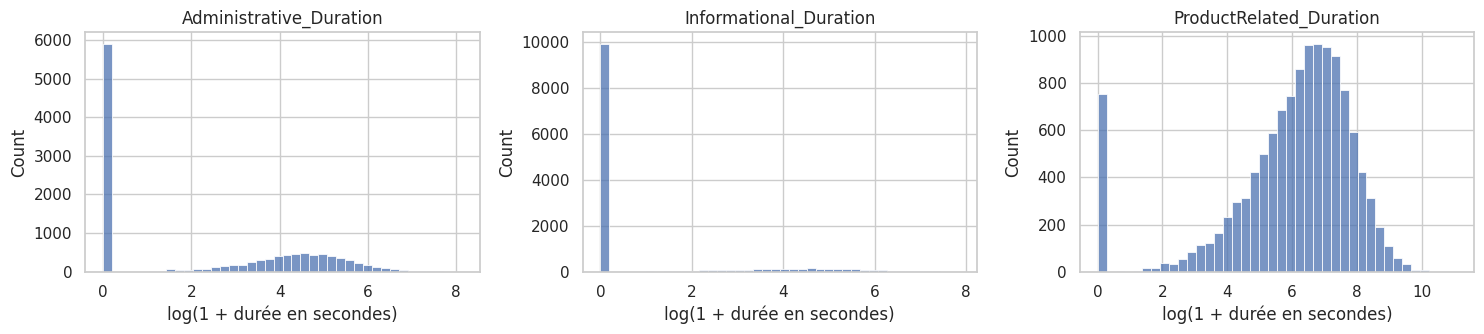

Asymétrie (skew) : {'Administrative_Duration': 5.6, 'Informational_Duration': 7.6, 'ProductRelated_Duration': 7.3}
Pages produits : médiane 10 min | 99e centile 2.4 h | max 17.8 h
Sessions de plus d'1 h sur les pages produits : 867
Sessions sans aucune page vue : 6
Administrative  pages > 0 mais durée = 0 :  135 | pages = 0 mais durée > 0 : 0
Informational   pages > 0 mais durée = 0 :  226 | pages = 0 mais durée > 0 : 0
ProductRelated  pages > 0 mais durée = 0 :  717 | pages = 0 mais durée > 0 : 0


In [98]:
DUR_COLS = ["Administrative_Duration", "Informational_Duration", "ProductRelated_Duration"]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, DUR_COLS):
    sns.histplot(np.log1p(raw[col]), bins=40, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("log(1 + durée en secondes)")
plt.tight_layout()
plt.show()

print("Asymétrie (skew) :", raw[DUR_COLS].skew().round(1).to_dict())
pr = raw["ProductRelated_Duration"]
print(f"Pages produits : médiane {pr.median() / 60:.0f} min | 99e centile {pr.quantile(0.99) / 3600:.1f} h | max {pr.max() / 3600:.1f} h")
print("Sessions de plus d'1 h sur les pages produits :", int((pr > 3600).sum()))
print("Sessions sans aucune page vue :", int((raw[["Administrative", "Informational", "ProductRelated"]].sum(axis=1) == 0).sum()))

# Google Analytics ne mesure pas la durée de la dernière page vue : des pages > 0 avec une durée = 0 sont normales
for pages, duree in [("Administrative", "Administrative_Duration"), ("Informational", "Informational_Duration"),
                     ("ProductRelated", "ProductRelated_Duration")]:
    print(f"{pages:15s} pages > 0 mais durée = 0 : {int(((raw[pages] > 0) & (raw[duree] == 0)).sum()):4d}"
          f" | pages = 0 mais durée > 0 : {int(((raw[pages] == 0) & (raw[duree] > 0)).sum())}")

**Lecture.** Même en échelle logarithmique, les durées sont très asymétriques (asymétrie de 5,6 à 7,6) avec un gros pic à 0 : beaucoup de sessions ne passent aucun temps sur un type de page, et quelques-unes durent des heures (maximum 17,8 h).

### 1.3 La cible : classes déséquilibrées

Revenue
False    10422
True      1908
Name: count, dtype: int64
Revenue
False    0.845
True     0.155
Name: proportion, dtype: float64


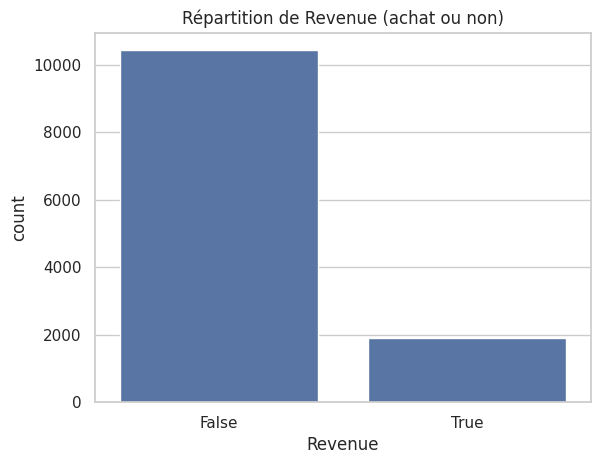

In [99]:
print(raw[TARGET].value_counts())
print(raw[TARGET].value_counts(normalize=True).round(3))
sns.countplot(x=TARGET, data=raw)
plt.title("Répartition de Revenue (achat ou non)")
plt.show()

**Lecture.** 1 908 sessions sur 12 330 (15,5 %) finissent par un achat : la classe « achat » est minoritaire, c'est elle qu'il faudra savoir repérer.

### 1.4 Les catégories : mois et type de visiteur

In [100]:
print(raw["Month"].value_counts())       # remarque : 'June' en entier, pas de janvier ni d'avril
print(raw["VisitorType"].value_counts())

Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64
VisitorType
Returning_Visitor    10551
New_Visitor           1694
Other                   85
Name: count, dtype: int64


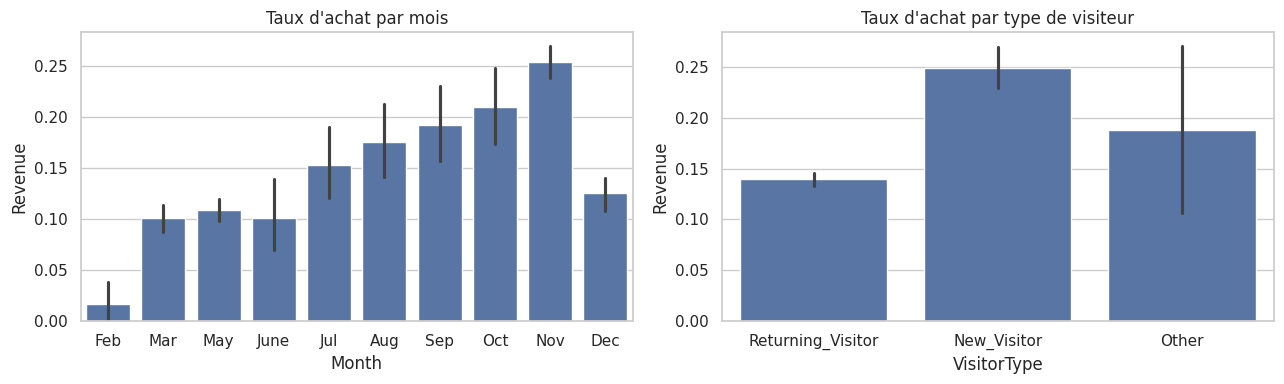

Taux d'achat par mois : {'Feb': 0.016, 'Mar': 0.101, 'May': 0.109, 'June': 0.101, 'Jul': 0.153, 'Aug': 0.176, 'Sep': 0.192, 'Oct': 0.209, 'Nov': 0.254, 'Dec': 0.125}
Taux d'achat par type de visiteur : {'New_Visitor': 0.249, 'Other': 0.188, 'Returning_Visitor': 0.139}


In [101]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
sns.barplot(x="Month", y=TARGET, data=raw, order=order, ax=axes[0])
axes[0].set_title("Taux d'achat par mois")
sns.barplot(x="VisitorType", y=TARGET, data=raw, ax=axes[1])
axes[1].set_title("Taux d'achat par type de visiteur")
plt.tight_layout()
plt.show()

print("Taux d'achat par mois :", raw.groupby("Month")[TARGET].mean().reindex(order).round(3).to_dict())
print("Taux d'achat par type de visiteur :", raw.groupby("VisitorType")[TARGET].mean().round(3).to_dict())

**Lecture.** Le taux d'achat varie beaucoup selon le mois : 25,4 % en novembre et 20,9 % en octobre, contre 1,6 % en février. Les nouveaux visiteurs achètent plus souvent (24,9 %) que ceux qui reviennent (13,9 %), alors qu'ils sont beaucoup moins nombreux.

### 1.5 Le piège `PageValues`

In [102]:
has_value = raw[LEAKY_COL] > 0
print("Taux d'achat quand PageValues > 0 :", round(raw.loc[has_value, TARGET].mean(), 3),
      "(", int(has_value.sum()), "sessions )")
print("Taux d'achat quand PageValues = 0 :", round(raw.loc[~has_value, TARGET].mean(), 3),
      "(", int((~has_value).sum()), "sessions )")

Taux d'achat quand PageValues > 0 : 0.563 ( 2730 sessions )
Taux d'achat quand PageValues = 0 : 0.039 ( 9600 sessions )


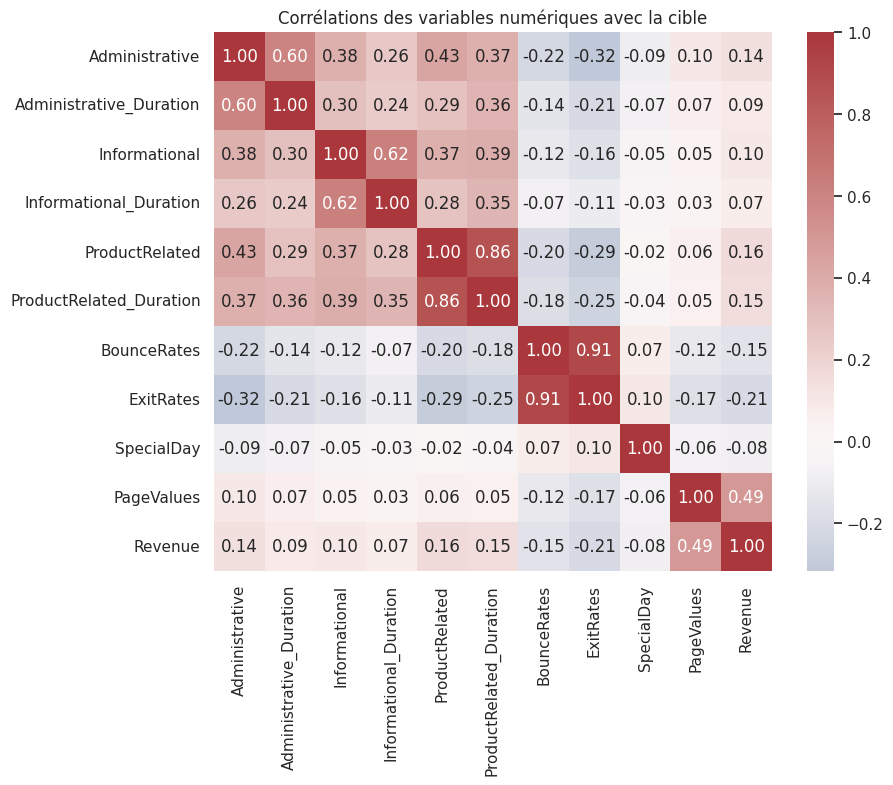

Corrélation avec l'achat : {'ExitRates': -0.21, 'BounceRates': -0.15, 'SpecialDay': -0.08, 'Informational_Duration': 0.07, 'Administrative_Duration': 0.09, 'Informational': 0.1, 'Administrative': 0.14, 'ProductRelated_Duration': 0.15, 'ProductRelated': 0.16, 'PageValues': 0.49}
BounceRates / ExitRates : 0.91 | ProductRelated / ProductRelated_Duration : 0.86


In [103]:
num = NUM_COLS + [LEAKY_COL]
plt.figure(figsize=(9, 7))
sns.heatmap(raw[num + [TARGET]].astype(float).corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Corrélations des variables numériques avec la cible")
plt.show()

corr = raw[num + [TARGET]].astype(float).corr()
print("Corrélation avec l'achat :", corr[TARGET].drop(TARGET).round(2).sort_values().to_dict())
print("BounceRates / ExitRates :", round(corr.loc["BounceRates", "ExitRates"], 2),
      "| ProductRelated / ProductRelated_Duration :", round(corr.loc["ProductRelated", "ProductRelated_Duration"], 2))

**Lecture.** `PageValues` est de loin la variable la plus liée à l'achat (0,49) ; viennent ensuite `ExitRates` (−0,21) et le nombre de pages produits (0,16). `BounceRates` et `ExitRates` sont presque redondantes (0,91), comme le nombre de pages produits et leur durée (0,86).

### 1.5 bis Qu'est-ce qui distingue les acheteurs ?

Comparaison acheteurs / non-acheteurs sur les variables **connues pendant la visite** (donc sans `PageValues`).

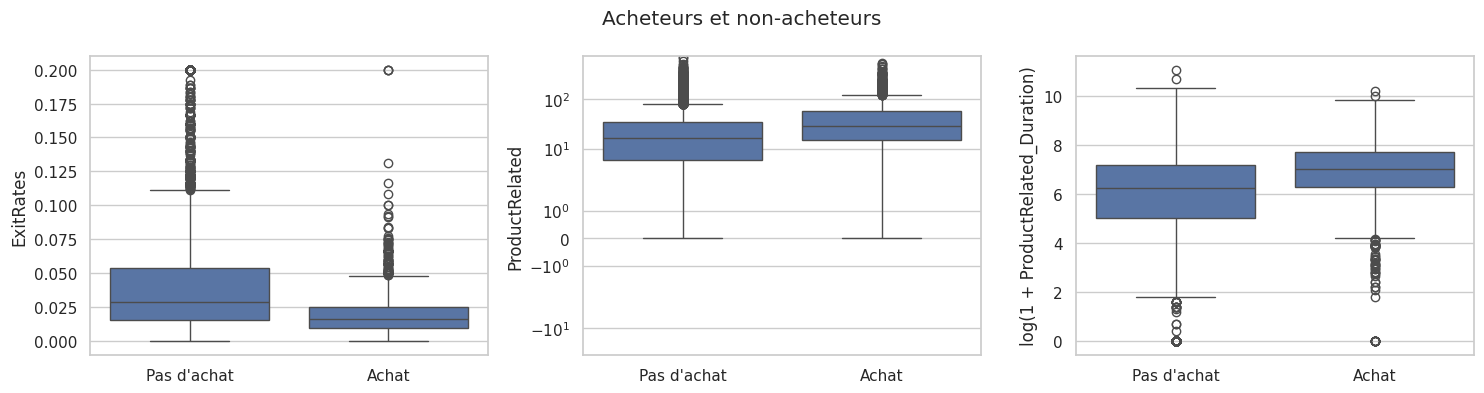

         ExitRates  BounceRates  ProductRelated  ProductRelated_Duration
Revenue                                                                 
False        0.029        0.004            16.0                  510.190
True         0.016        0.000            29.0                 1109.906

Corrélation de Spearman avec l'achat :
ExitRates                 -0.25
BounceRates               -0.15
SpecialDay                -0.09
Informational_Duration     0.11
Informational              0.11
Administrative_Duration    0.16
Administrative             0.17
ProductRelated             0.20
ProductRelated_Duration    0.22
PageValues                 0.63
dtype: float64


In [104]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(x=TARGET, y="ExitRates", data=raw, ax=axes[0])
sns.boxplot(x=TARGET, y="ProductRelated", data=raw, ax=axes[1])
axes[1].set_yscale("symlog")
sns.boxplot(x=TARGET, y=np.log1p(raw["ProductRelated_Duration"]), data=raw, ax=axes[2])
axes[2].set_ylabel("log(1 + ProductRelated_Duration)")
for ax in axes:
    ax.set_xticks([0, 1], ["Pas d'achat", "Achat"])
    ax.set_xlabel("")
plt.suptitle("Acheteurs et non-acheteurs")
plt.tight_layout()
plt.show()

print(raw.groupby(TARGET)[["ExitRates", "BounceRates", "ProductRelated", "ProductRelated_Duration"]].median().round(3))

# Corrélation de Spearman (sur les rangs) : plus fiable que Pearson pour des variables très asymétriques
print("\nCorrélation de Spearman avec l'achat :")
print(raw[NUM_COLS + [LEAKY_COL]].corrwith(raw[TARGET].astype(int), method="spearman").sort_values().round(2))

**Lecture.** Les acheteurs ont un taux de sortie médian presque deux fois plus bas (0,016 contre 0,029), regardent presque deux fois plus de pages produits (29 contre 16) et y passent plus de deux fois plus de temps (1 110 s contre 510 s) : l'intérêt pour les produits se voit pendant la visite, sans `PageValues`.

### 1.5 ter Variables à surveiller : `SpecialDay` et codes rares

In [105]:
print("SpecialDay > 0 seulement pour les mois :", sorted(raw.loc[raw["SpecialDay"] > 0, "Month"].unique()))
print("(proximité de la Saint-Valentin en février et de la fête des mères en mai : redondant en partie avec Month)\n")

for col in ["OperatingSystems", "Browser", "Region", "TrafficType"]:
    counts = raw[col].value_counts()
    rares = counts[counts < 30]
    print(f"{col:16s} {len(counts):2d} codes, dont {len(rares)} rares (< 30 sessions) : {rares.to_dict()}")

SpecialDay > 0 seulement pour les mois : ['Feb', 'May']
(proximité de la Saint-Valentin en février et de la fête des mères en mai : redondant en partie avec Month)

OperatingSystems  8 codes, dont 3 rares (< 30 sessions) : {6: 19, 7: 7, 5: 6}
Browser          13 codes, dont 3 rares (< 30 sessions) : {12: 10, 11: 6, 9: 1}
Region            9 codes, dont 0 rares (< 30 sessions) : {}
TrafficType      20 codes, dont 6 rares (< 30 sessions) : {19: 17, 14: 13, 18: 10, 16: 3, 12: 1, 17: 1}


### 1.6 Constats

- **Qualité des données :** il n'y a aucune valeur manquante. On trouve 125 doublons (201 lignes concernées). En les regardant (1.2 bis), ce sont tous des rebonds (taux de rebond maximal de 0,2) sans achat, le plus souvent une seule page produit vue en 0 seconde. Ce sont donc sûrement des visites différentes qui se ressemblent, pas des erreurs de saisie. 6 sessions n'ont aucune page vue.
- **Durées :** elles sont très étalées. La moitié des visites passent moins de 10 minutes sur les pages produits, mais 867 visites dépassent 1 heure et la plus longue dure presque 18 heures (sans doute un onglet oublié). On les garde. On voit aussi 717 visites avec des pages produits vues mais une durée de 0 : sans doute parce que Google Analytics ne compte pas le temps passé sur la dernière page d'une visite (on ne peut pas le vérifier avec ces données).
- **Déséquilibre :** seulement 1 908 visites sur 12 330 finissent par un achat (15,5 %). 84,5 % des visites ne finissent pas par un achat : répondre toujours « pas d'achat » aurait l'air juste la plupart du temps sans trouver un seul acheteur. Le découpage devra donc garder la même proportion d'achats dans l'entraînement et dans le test (`stratify`).
- **`PageValues` :** quand elle est supérieure à 0, 56 % des visites achètent ; quand elle vaut 0, seulement 4 %. C'est la variable la plus liée à l'achat (0,63 en Spearman). Le problème : elle est calculée avec les achats, donc on ne la connaît pas vraiment pendant la visite. C'est la fuite repérée au cadrage : on l'exclut de la préparation (partie 2).
- **Ce qui distingue les acheteurs (1.5 bis) :** ils regardent presque deux fois plus de pages produits (29 contre 16 en médiane), y restent plus longtemps et quittent moins vite le site (`ExitRates` : −0,25).
- **Mois et visiteurs :** il manque janvier et avril, et « June » était écrit en entier. D'après les graphiques de la section 1.4, on achète beaucoup plus en novembre qu'en février, et les nouveaux visiteurs achètent plus souvent que les habitués. `SpecialDay` n'apparaît qu'en février et en mai, donc elle répète en partie l'information du mois.
- **Codes en nombres :** `OperatingSystems`, `Browser`, `Region` et `TrafficType` sont des codes, pas des quantités : la région 8 n'est pas « plus » que la région 2. On les encode en one-hot. 12 codes ont moins de 30 visites ; on les garde pour l'instant.

# Partie 2 · Préparation (étape 2)

### 2.1 Nettoyage sans apprentissage

**Pourquoi retirer les doublons alors que ce sont probablement de vraies visites (section 1.2 bis) ?** Une même ligne pourrait se retrouver à la fois dans l'entraînement et dans le test : le modèle serait alors évalué sur des exemples déjà vus (fuite). Les 125 lignes retirées sont toutes des rebonds sans achat ; l'effet sur la répartition est négligeable (15,5 % → 15,6 % d'achats). Choix prudent, assumé.

**Colonnes exclues et pourquoi**

| Colonne | Décision | Raison |
| --- | --- | --- |
| (identifiant) | aucune à retirer | Le jeu n'a pas de colonne d'identifiant : chaque ligne est une session anonyme (vérifié en 1.2 avec `raw.info()`) |
| `PageValues` | exclue de la préparation | Fuite repérée au cadrage : elle est calculée à partir des transactions, donc pas vraiment connue pendant la visite ; elle est pourtant très liée à l'achat (1.5) |
| `Revenue` | séparée des variables | C'est la cible, elle ne doit jamais servir d'entrée |

Toutes les autres colonnes sont gardées : 9 numériques, 6 catégorielles et `Weekend`.

In [106]:
df = clean(raw)
print("Lignes avant :", len(raw), "| après suppression des doublons :", len(df))
print(sorted(df["Month"].unique()))

Lignes avant : 12330 | après suppression des doublons : 12205
['Aug', 'Dec', 'Feb', 'Jul', 'Jun', 'Mar', 'May', 'Nov', 'Oct', 'Sep']


### 2.2 Séparer **avant** de préparer

Le découpage est stratifié pour garder environ 15 % d'achats dans le train **et** dans le test.

In [107]:
X_train, X_test , y_train, y_test = split(df)
print("Entraînement :", X_train.shape, "| Test :" , X_test.shape)
print("Taux d'achat train :", round(y_train.mean(), 3), "| test :" ,
round(y_test.mean(),3))

Entraînement : (9764, 17) | Test : (2441, 17)
Taux d'achat train : 0.156 | test : 0.156


### 2.3 Encoder et normaliser avec un `ColumnTransformer`

`fit` sur l'entraînement uniquement ; le test est seulement **transformé**. `PageValues` n'est dans aucune liste de colonnes : `remainder="drop"` la retire.

In [108]:
prep = make_preprocessor()
Xtr = prep.fit_transform(X_train)   # apprend moyennes, écarts-types et catégories sur l'entraînement seulement
Xte = prep.transform(X_test)        # applique au test ce qui a été appris
print("Entraînement :", Xtr.shape, "| Test :", Xte.shape)


noms = list(prep.get_feature_names_out())
print("PageValues encore présente ?", any("PageValues" in n for n in noms))
print("Exemples de colonnes créées :", noms[:12])

Entraînement : (9764, 72) | Test : (2441, 72)
PageValues encore présente ? False
Exemples de colonnes créées : ['num__Administrative', 'num__Administrative_Duration', 'num__Informational', 'num__Informational_Duration', 'num__ProductRelated', 'num__ProductRelated_Duration', 'num__BounceRates', 'num__ExitRates', 'num__SpecialDay', 'cat__Month_Aug', 'cat__Month_Dec', 'cat__Month_Feb']


### 2.4 Préparer une nouvelle session (comme le fera l'application)

In [109]:
nouvelle_session = X_test.iloc[[0]]
display(nouvelle_session)
print(prep.transform(nouvelle_session).round(2))

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
11640,0,0.0,0,0.0,12,482.5,0.02,0.04,0.0,0.0,Nov,1,2,1,10,Returning_Visitor,0


[[-0.7  -0.46 -0.4  -0.24 -0.45 -0.38 -0.01 -0.03 -0.31  0.    0.    0.
   0.    0.    0.    0.    1.    0.    0.    0.    0.    1.    1.    0.
   0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    1.
   0.    0.    0.    0.    0.    0.    0.    1.    0.    0.    0.    0.
   0.    0.    0.    0.    0.    1.    0.    0.    0.    0.    0.    0.
   0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.  ]]


## Bilan J1

- **Ce qu'on retient des données :** un seul site sur un an (sans janvier ni avril), aucune valeur manquante, 125 doublons. Les classes sont déséquilibrées : 15,5 % d'achats. Les acheteurs regardent plus de pages produits, y restent plus longtemps et partent moins vite ; on achète surtout en fin d'année (novembre) et les nouveaux visiteurs achètent plus souvent. `PageValues` est très liée à l'achat mais c'est une fuite : elle est exclue.
- **Nos choix de préparation :** doublons retirés avant de découper, pour qu'une même ligne ne se retrouve pas à la fois dans l'entraînement et dans le test (15,5 % → 15,6 % d'achats). Découpage 80 / 20 stratifié (graine 42) **avant** toute préparation : 9 764 sessions pour l'entraînement, 2 441 pour le test, mis de côté. Puis `ColumnTransformer` appris sur l'entraînement seulement : `StandardScaler` pour les 9 nombres, `OneHotEncoder` pour les 6 codes, `Weekend` gardé en 0 / 1 ; résultat : 72 colonnes.
- **Pour la suite (J2) :** entraîner les premiers modèles sur cette préparation.